## Imports e caminhos

In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import random_split
import matplotlib.pyplot as plt
from pathlib import Path
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.tensorboard import SummaryWriter

# raiz do repositório: sobe as pastas até achar o mkdocs.yml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mkdocs.yml").exists())
DATA = ROOT / "data"                              # MNIST já baixado
LOGS = ROOT / "Claude outputs" / "tensorboard"    # onde o TensorBoard grava

print(ROOT)

C:\Insper\8-Semestre\Redes Neurais\ann-dl


In [2]:
train_full = datasets.MNIST(DATA, train=True, download=True, transform=transforms.ToTensor())
test = datasets.MNIST(DATA, train=False, download=True, transform=transforms.ToTensor())
train, val = random_split(train_full, [50_000, 10_000],
                          generator=torch.Generator().manual_seed(42))

In [3]:
def to_tensors(dataset):
    """Empilha um dataset de imagens (1, 28, 28) em X (N, 784) e y (N,)."""
    X = torch.stack([img for img, _ in dataset]).view(-1, 784)
    y = torch.tensor([label for _, label in dataset])
    return X, y


X_train, y_train = to_tensors(train)
X_val, y_val = to_tensors(val)
X_test, y_test = to_tensors(test)

print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([50000, 784]) torch.Size([10000, 784]) torch.Size([10000, 784])


In [4]:
class VAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        # encoder: 784 -> 512 -> 256, ReLU depois de cada
        self.encoder = nn.Sequential(
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
        )
        # head_mu e head_logvar: 256 -> d (sem ativação)
        self.head_mu = nn.Linear(256, d)
        self.head_logvar = nn.Linear(256, d)
        # decoder: d -> 256 -> 512 -> 784, Sigmoid no fim
        self.decoder = nn.Sequential(
            nn.Linear(d, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid(),
        )

    def encode(self, x):
        # imagem -> mu, logvar
        h = self.encoder(x)
        mu = self.head_mu(h)
        logvar = self.head_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        # mu, logvar -> z
        std = torch.exp(0.5 * logvar)   # sigma = exp(log sigma² / 2)
        eps = torch.randn_like(std)     # epsilon ~ N(0, I), mesmo formato de std
        z = mu + std * eps
        return z

    def forward(self, x):
        # encode -> reparameterize -> decoder
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decoder(z)
        return x_hat, mu, logvar

In [5]:
torch.manual_seed(42)
model = VAE(d=16)
x_hat, mu, logvar = model(X_train[:4])
print(x_hat.shape, mu.shape, logvar.shape)

torch.Size([4, 784]) torch.Size([4, 16]) torch.Size([4, 16])


## Loss

Devolve os dois termos separados, em nats por imagem:

- **reconstrução:** BCE somada nos 784 pixels, dividida pelo número de imagens
- **KL:** ½ Σ (μ² + σ² − 1 − log σ²), somada nas d dimensões, dividida pelo número de imagens

In [6]:
def vae_loss(x_hat, x, mu, logvar):
    """Devolve os dois termos da loss separados, em nats por imagem."""
    batch = x.shape[0]
    # reconstrução: BCE somada nos 784 pixels e dividida pelo nº de imagens
    # (reduction="mean" dividiria também por 784 e encolheria esse termo)
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / batch
    # KL na forma fechada: ½ Σ (μ² + σ² − 1 − log σ²), somada nas d dimensões
    kl = 0.5 * torch.sum(mu.pow(2) + logvar.exp() - 1 - logvar) / batch
    return recon, kl


# modelo ainda sem treino: reconstrução perto de 544 e KL perto de 0
recon, kl = vae_loss(x_hat, X_train[:4], mu, logvar)
print(f"sem treino: reconstrução {recon.item():.2f}  KL {kl.item():.4f}")

sem treino: reconstrução 544.72  KL 0.0377


## Treino

`evaluate` mede reconstrução e KL num conjunto inteiro, sem treinar.
`train_vae` faz o laço: para cada batch, forward → loss → `backward()` → `step()`.

In [7]:
@torch.no_grad()  # só avalia: não calcula gradiente nem mexe nos pesos
def evaluate(model, X, batch_size=1000):
    """Reconstrução e KL médias (nats por imagem) de um conjunto inteiro."""
    model.eval()
    recon_total, kl_total = 0.0, 0.0
    for i in range(0, len(X), batch_size):
        x = X[i:i + batch_size]
        x_hat, mu, logvar = model(x)
        recon, kl = vae_loss(x_hat, x, mu, logvar)
        recon_total += recon.item() * len(x)  # volta à soma do batch, para fazer a média no fim
        kl_total += kl.item() * len(x)
    return recon_total / len(X), kl_total / len(X)


def train_vae(d, epochs=20, batch_size=128, lr=1e-3):
    """Treina um VAE com latente de dimensão d e devolve o modelo e o histórico por época."""
    torch.manual_seed(42)  # semente antes de construir o modelo (regra técnica)
    model = VAE(d)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_recon": [], "train_kl": [], "val_recon": [], "val_kl": []}

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X_train))  # embaralha o treino a cada época
        recon_total, kl_total = 0.0, 0.0
        for i in range(0, len(X_train), batch_size):
            x = X_train[perm[i:i + batch_size]]
            x_hat, mu, logvar = model(x)              # forward
            recon, kl = vae_loss(x_hat, x, mu, logvar)
            loss = recon + kl                         # o que o otimizador minimiza
            opt.zero_grad()
            loss.backward()                           # gradiente de todos os pesos
            opt.step()                                # ajusta os pesos
            recon_total += recon.item() * len(x)
            kl_total += kl.item() * len(x)

        # treino: média da época; validação: avaliada no fim da época
        hist["train_recon"].append(recon_total / len(X_train))
        hist["train_kl"].append(kl_total / len(X_train))
        val_recon, val_kl = evaluate(model, X_val)
        hist["val_recon"].append(val_recon)
        hist["val_kl"].append(val_kl)
        print(f"d={d} época {epoch + 1:2d}: treino recon {hist['train_recon'][-1]:.2f} "
              f"KL {hist['train_kl'][-1]:.2f} | val recon {val_recon:.2f} KL {val_kl:.2f}")

    return model, hist

O treino leva cerca de 3 minutos na CPU.

In [8]:
model, hist = train_vae(d=16)

d=16 época  1: treino recon 175.96 KL 6.83 | val recon 129.69 KL 12.45


d=16 época  2: treino recon 116.21 KL 14.53 | val recon 107.82 KL 15.53


d=16 época  3: treino recon 102.85 KL 16.23 | val recon 99.24 KL 16.77


d=16 época  4: treino recon 96.79 KL 17.12 | val recon 95.43 KL 17.35


d=16 época  5: treino recon 93.00 KL 17.86 | val recon 92.50 KL 17.89


...

d=16 época 16: treino recon 81.01 KL 20.05 | val recon 82.10 KL 19.84


d=16 época 17: treino recon 80.52 KL 20.11 | val recon 81.76 KL 20.15


d=16 época 18: treino recon 80.27 KL 20.15 | val recon 81.17 KL 20.64


d=16 época 19: treino recon 79.97 KL 20.19 | val recon 81.98 KL 19.85


d=16 época 20: treino recon 79.71 KL 20.20 | val recon 81.46 KL 19.92


### Números finais no teste

A única vez em que o conjunto de teste é usado.

In [9]:
test_recon, test_kl = evaluate(model, X_test)
print(f"teste (d=16): recon {test_recon:.2f}  KL {test_kl:.2f}  "
      f"-ELBO {test_recon + test_kl:.2f} nats/imagem")
print(f"validação KL: 1ª época {hist['val_kl'][0]:.2f}, última época {hist['val_kl'][-1]:.2f}")

teste (d=16): recon 80.82  KL 19.96  -ELBO 100.78 nats/imagem
validação KL: 1ª época 12.45, última época 19.92


### Figura 1 — os dois termos da loss por época

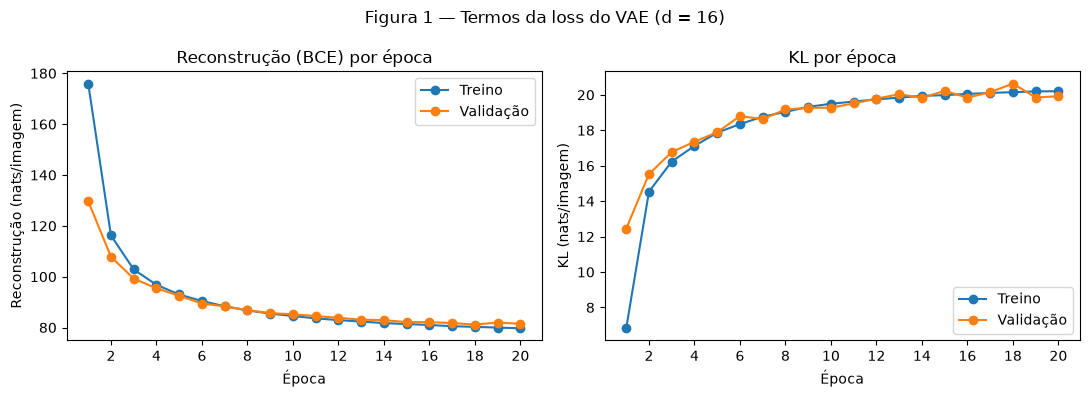

In [10]:
epochs = range(1, len(hist["train_recon"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(epochs, hist["train_recon"], marker="o", label="Treino")
ax1.plot(epochs, hist["val_recon"], marker="o", label="Validação")
ax1.set_title("Reconstrução (BCE) por época")
ax1.set_xlabel("Época")
ax1.set_ylabel("Reconstrução (nats/imagem)")
ax1.legend()
ax2.plot(epochs, hist["train_kl"], marker="o", label="Treino")
ax2.plot(epochs, hist["val_kl"], marker="o", label="Validação")
ax2.set_title("KL por época")
ax2.set_xlabel("Época")
ax2.set_ylabel("KL (nats/imagem)")
ax2.legend()
for ax in (ax1, ax2):
    ax.set_xticks(range(2, len(epochs) + 1, 2))  # épocas inteiras no eixo x
fig.suptitle("Figura 1 — Termos da loss do VAE (d = 16)")
fig.tight_layout()
plt.show()

## Reconstruções e amostras

### Figura 2 — primeira imagem de teste de cada dígito e sua reconstrução

A reconstrução decodifica μ direto, sem sortear z.

índices de teste da Figura 2: [3, 2, 1, 18, 4, 8, 11, 0, 61, 7]


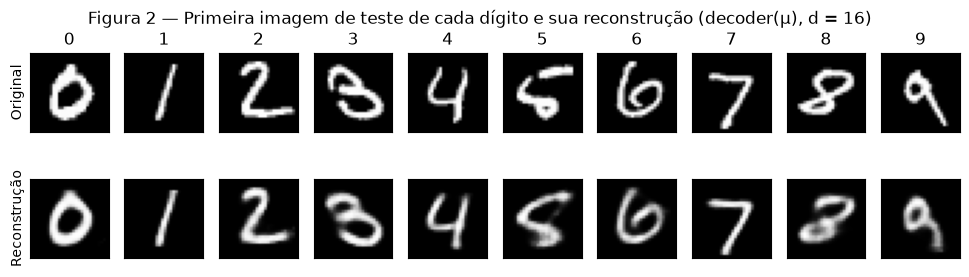

In [11]:
model.eval()
first_idx = [int((y_test == digit).nonzero()[0]) for digit in range(10)]
print("índices de teste da Figura 2:", first_idx)
with torch.no_grad():
    mu, _ = model.encode(X_test[first_idx])
    recon_imgs = model.decoder(mu)  # decodifica μ, sem sortear z

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for col in range(10):
    axes[0, col].imshow(X_test[first_idx[col]].view(28, 28), cmap="gray")
    axes[1, col].imshow(recon_imgs[col].view(28, 28), cmap="gray")
    axes[0, col].set_title(str(col))
    for row in range(2):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstrução")
fig.suptitle("Figura 2 — Primeira imagem de teste de cada dígito e sua reconstrução (decoder(μ), d = 16)")
plt.show()

### Figura 3 — 64 imagens geradas a partir de z ~ N(0, I)

Aqui o encoder não é usado: z é sorteado e vai direto para o decoder.

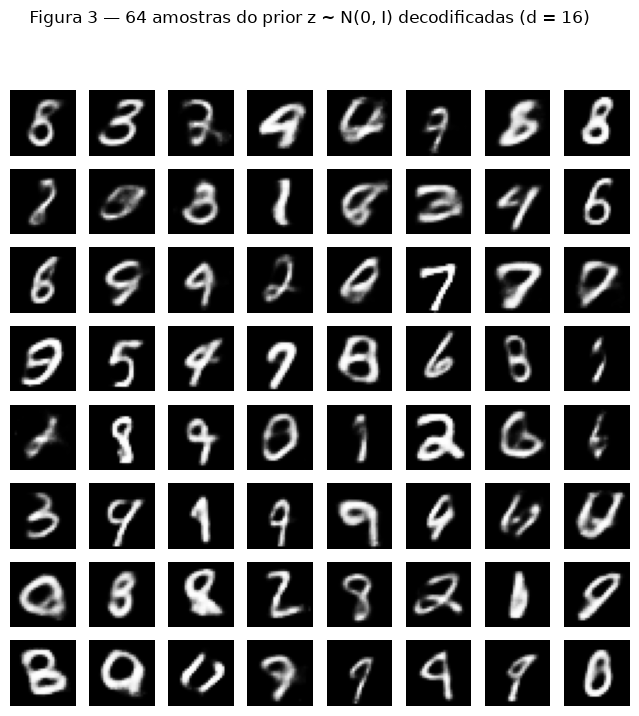

In [12]:
torch.manual_seed(0)
with torch.no_grad():
    z = torch.randn(64, 16)          # sorteio do prior, escrito à mão
    samples = model.decoder(z)

fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for ax, img in zip(axes.flat, samples):
    ax.imshow(img.view(28, 28), cmap="gray")
    ax.axis("off")
fig.suptitle("Figura 3 — 64 amostras do prior z ~ N(0, I) decodificadas (d = 16)")
plt.show()